In [2]:
import numpy as np
#from numpy.linalg import eigvals, eigvalsh
#from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh,eigs
import matplotlib.pyplot as plt

import Minimal_Model_1D as M

In [3]:
###defining constants##

hbar = 1.055*10**(-34);   #in J-s
ee = 1.602*10**(-19);     #in C
hbar_mev = hbar/ee*1000   # in meV-s
me = 9.11*10**(-31);      #in kg
hbm = hbar**2*1000/2/me/ee/(1e-18) #in meV (nm)**2

Perturbative regime for cubic SO LY = 10

In [8]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.0507     # proximitized Ge 
MEFF_SM = 0.0507     # Ge

LY = 10            # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  1 + OMEGA   #in between two subbands
MU_SM =  1 + OMEGA   #in between two subbands

ALPHAT = np.linspace(10, 1000, 21)

K = 12

Ep_cu = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu
    
    if i%10==0:
        print(i)


0
10
20


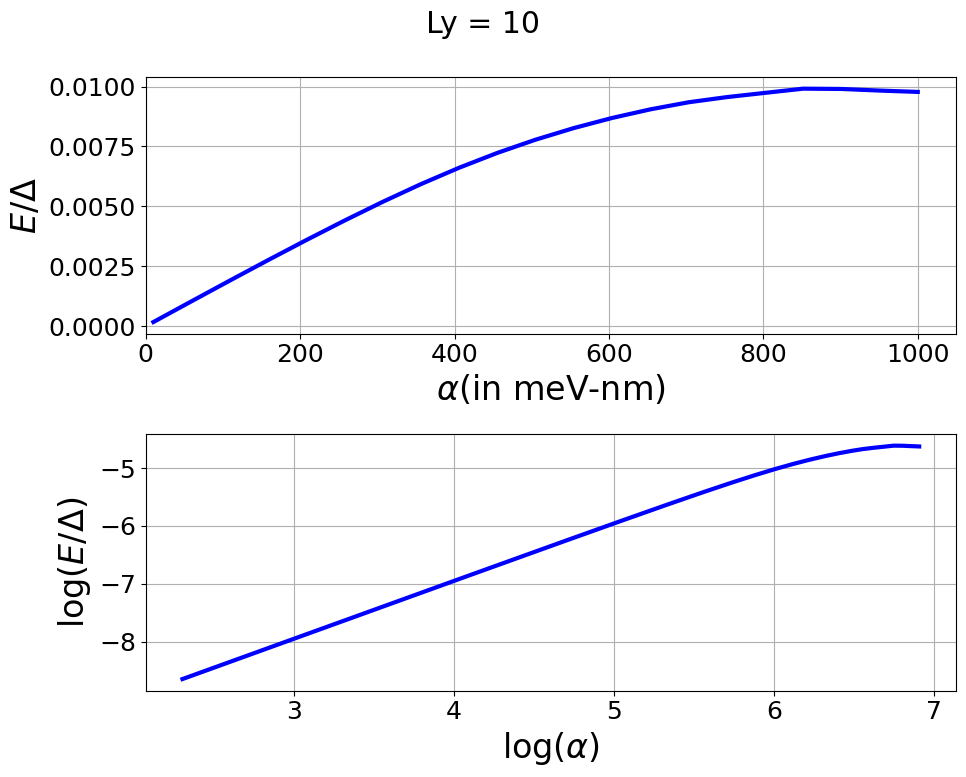

In [9]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]


plt.subplot(2,1,1)
plt.plot((ALPHAT), (Ep_Split_cu/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(2,1,2)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_cu/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
#plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()

In [14]:
import math

In [19]:
math.exp(6.6)

735.0951892419727

In [8]:
### Plotting spin splitting while varying width ###

NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.0507     # proximitized Ge 
MEFF_SM = 0.0507    # Ge

NSC = 1800
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 400  #meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm

LY = np.linspace(20, 100, 51)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SM = 1 + OMEGA        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 1 + OMEGA

K = 12

Ep_cu = np.empty((LY.shape[0],K))
#Kappa = np.empty((LY.shape[0],1) )

for i in range(LY.shape[0]):

    Fcu = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hcu = Fcu.H_sys(PHI, so = 'cu')
    
    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu 
    
    if i%10==0:
        print(i)


0
10
20
30
40
50


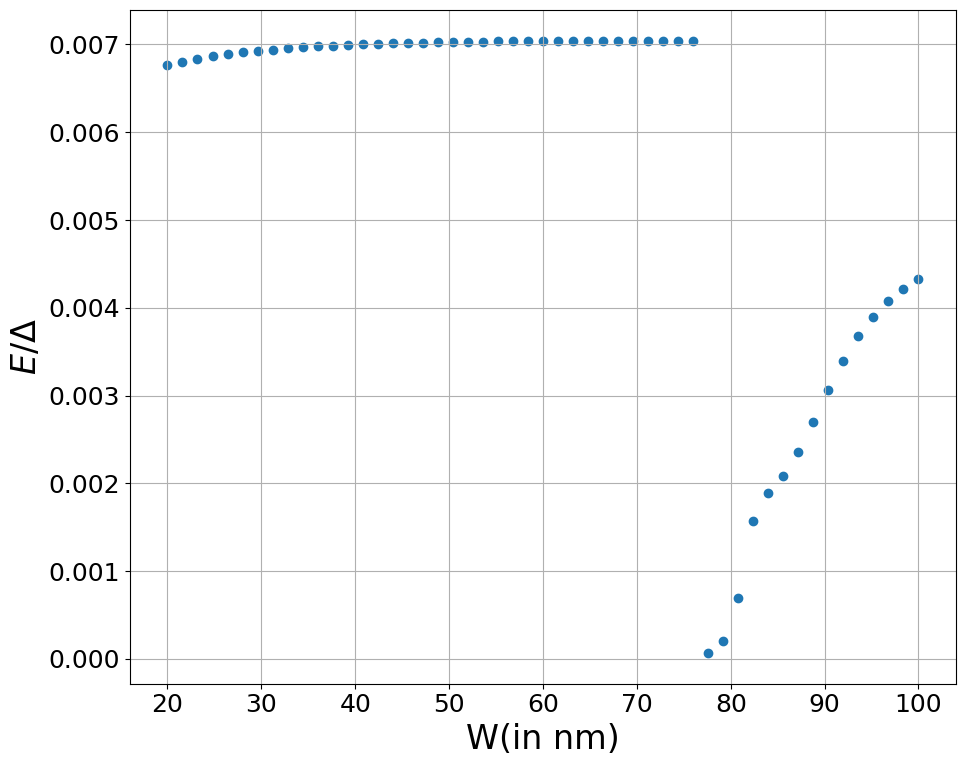

In [9]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

plt.scatter(LY, Ep_Split_cu/DELTA)

plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()

In [12]:
### Plotting spin splitting while varying width ###

NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.0507     # proximitized Ge 
MEFF_SM = 0.0507    # Ge

NSC = 1800
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 700  #meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm

LY = np.linspace(20, 100, 21)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SM = 1 + OMEGA        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 1 + OMEGA

K = 12

Ep_cu = np.empty((LY.shape[0],K))
#Kappa = np.empty((LY.shape[0],1) )

for i in range(LY.shape[0]):

    Fcu = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hcu = Fcu.H_sys(PHI, so = 'cu')
    
    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu 
    
    if i%10==0:
        print(i)


0
10
20


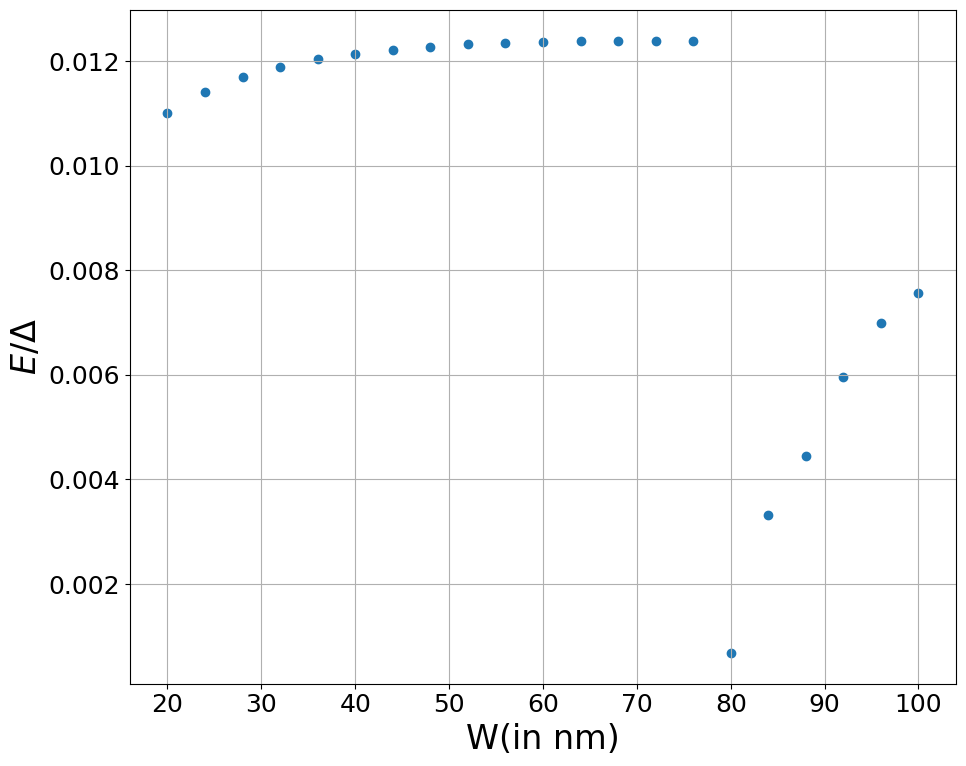

In [13]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

plt.scatter(LY, Ep_Split_cu/DELTA)

plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()

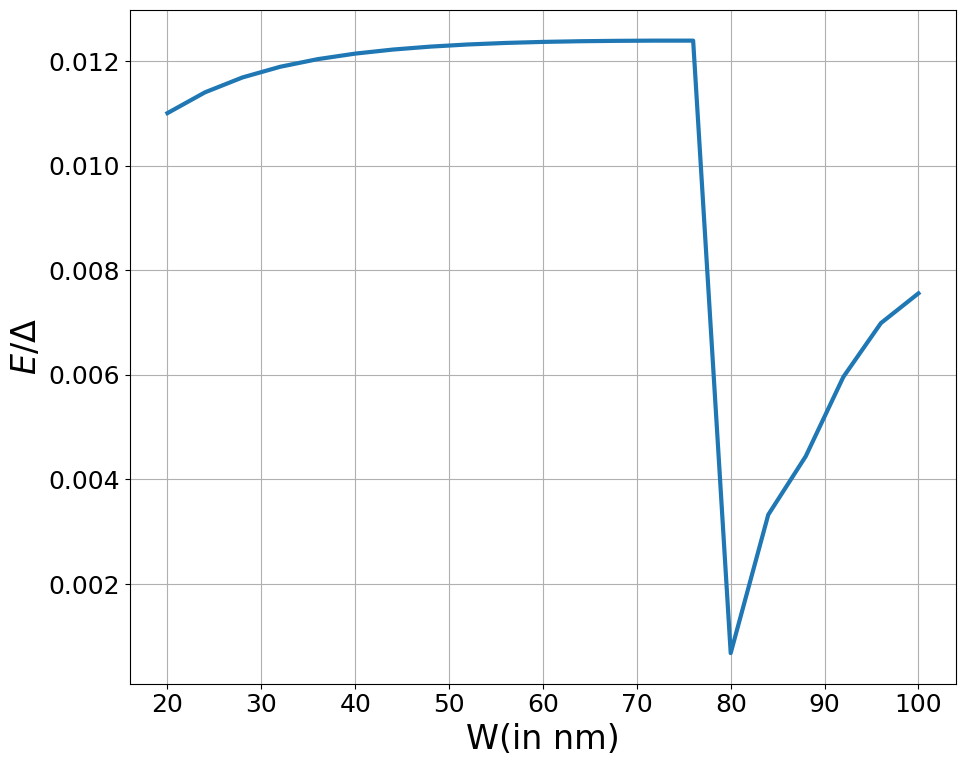

In [14]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

plt.plot(LY, Ep_Split_cu/DELTA, lw=3)

plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()